# A buffer is a declared rule

**Spatial methods · 15–25 minutes · map-centric edition**

A distinct map-centric 90-element source edition describes Leaflet/OSM maps with synthetic observations; its documented launcher returned 404.

**Learning question:** Which fictional points meet a distance rule, including its boundary?

This original index activity is **synthetic teaching analysis**. It uses invented values or authored metadata, no real people or sensitive locations, no remote APIs, and no AI model calls. It is a small companion to the source project, not a reproduction of that project's full course.

![Learning workflow](../../assets/capabilities.svg)

Original atlas diagram, James L. Tobias and contributors, CC BY 4.0; see [asset provenance](../../visual-provenance.ipynb).


## Predict before running

Measure straight-line distance from an invented origin in arbitrary planar units. Include points at exactly the radius. The local SVG draws a declared geometric rule, not travel access or a real geographic buffer. These fixtures have no missing values. Calculations require complete finite numeric coordinates and a nonnegative finite buffer radius; define a missing-data rule before introducing missing data.

Write a prediction and one assumption you would need to check. Run cells in order with **Shift+Enter**, or **Run → Run All Cells**. The next cell defines only local SVG display helpers; the following cell performs the analysis. Every graphic also prints its values as a text alternative.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Synthetic planar coordinates: {'A': (1, 1), 'B': (3, 0), 'C': (3, 2), 'D': (-2, -2)} ; radius: 3
Distance and inclusion: {'A': (1.414, True), 'B': (3.0, True), 'C': (3.606, False), 'D': (2.828, True)}


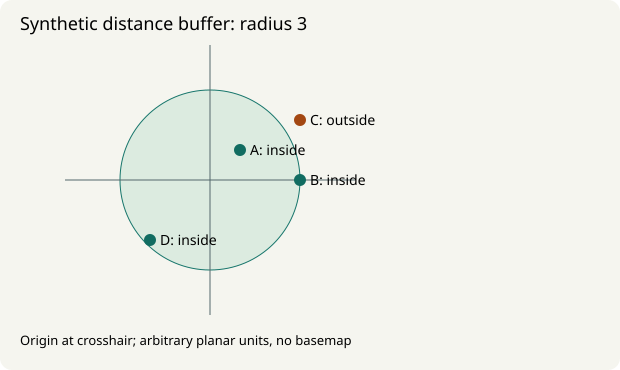

In [2]:
from math import hypot
points = {'A':(1,1), 'B':(3,0), 'C':(3,2), 'D':(-2,-2)}
radius = 3
distances = {name:hypot(x,y) for name,(x,y) in points.items()}
inside = {name:distance <= radius for name,distance in distances.items()}
print('Synthetic planar coordinates:', points, '; radius:', radius)
print('Distance and inclusion:', {name:(round(distances[name],3), inside[name]) for name in points})
title = f'Synthetic distance buffer: radius {radius:g}'
included = ', '.join(str(name) for name in points if inside[name]) or '(none)'
excluded = ', '.join(str(name) for name in points if not inside[name]) or '(none)'
description = f'Current radius: {radius:g} arbitrary planar units. Inside: {included}. Outside: {excluded}. Exact distances and inclusion are printed above.'
scale = 30
body = f'<circle cx="210" cy="180" r="{radius*scale}" fill="#dcebe0" stroke="#16756b"/><path d="M65 180H355M210 45V315" stroke="#53676b"/>'
for name,(x,y) in points.items():
    px, py = 210+x*scale, 180-y*scale
    color = '#116c61' if inside[name] else '#a34712'
    body += f'<circle cx="{px}" cy="{py}" r="6" fill="{color}"/><text x="{px+10}" y="{py+5}" font-family="sans-serif" font-size="14">{escape(str(name))}: {"inside" if inside[name] else "outside"}</text>'
body += f'<text x="20" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><text x="20" y="345" font-family="sans-serif" font-size="13">Origin at crosshair; arbitrary planar units, no basemap</text>'
svg(body, title, description, width=620, height=370)


## Interpret the result

A, B and D meet the rule. B lies exactly on the radius and is included by <=. A straight-line planar buffer says nothing about roads, obstacles, service eligibility or actual travel times. The invented coordinates have no geographic CRS.

Name the result, the assumption producing it, and one conclusion it cannot support. These are not clinical findings, causal effects or live model outputs.

## Change one thing

Change the radius to 2.5, then replace <= with < at radius 3. Predict the changed membership and explain why the boundary rule must accompany an exported layer.

Save a copy with **File → Save and Export Notebook As → Notebook** (or the file browser's Download command). Browser storage is local to this browser/profile; it is not a GitHub commit or shared database.


## Connect the idea

Compare this activity with another chapter on the same [learning path](../../index.ipynb). Keep the question, data status and interpretation visible when transferring a method.


## Sources, continuation and limits

**Source repository:** [JupyterLite-Maps-and-Spatial-Analyses](https://github.com/jltobias/JupyterLite-Maps-and-Spatial-Analyses).

**Source README:** [reviewed immutable version](https://github.com/jltobias/JupyterLite-Maps-and-Spatial-Analyses/blob/6949a8bf2f56c2e0b73a4da537beaf686cd00452/README.md); inspected 2026-11-01, commit `6949a8bf2f56`. Repository content and linked works keep their original terms. Summaries and exercises here are newly authored.

This source edition describes recognizable latitude/longitude locations, synthetic values and browser-side Leaflet/OpenStreetMap tiles; those external map requests have separate network and attribution requirements. None is loaded here. Its exact README launcher returned HTTP 404 on 2026-11-01 and remains listed as unavailable. Public source is usable independently of a deployed Pages site; no working source app is claimed.

- [Open documented source launcher](https://jltobias.github.io/JupyterLite-Maps-and-Spatial-Analyses/) — The exact root launcher documented by this source README; unavailable when checked. **Unavailable - HTTP 404**

**Runtime budget:** this default is fewer than 100 values and normally completes within seconds; allow 60 seconds per cell while first loading Python. Continue with the reviewed README's local JupyterLite build or GitHub Actions/Pages instructions. Its Leaflet/OpenStreetMap iframe maps require external tiles and browser networking; retain their attribution and verify source map behavior separately. The documented root launcher returned HTTP 404 on 2026-11-01. [Reviewed source README](https://github.com/jltobias/JupyterLite-Maps-and-Spatial-Analyses/blob/6949a8bf2f56c2e0b73a4da537beaf686cd00452/README.md).

[Central references](../../references.ipynb) · [Contribute](../../contributor-guide.ipynb)
